# Capítulo 4 — El modelo SDDE de Langevin con retardo

$$\frac{dG}{dt} = -\alpha\,\big(G(t-\tau_d) - (B(t)+\Delta_b)\big) + k_f\,S(t) + \beta_n\,\eta(t) \qquad (4.3)$$

| Sección | Resultado | Celda |
|---|---|---|
| 4.3 | Integrador (método de pasos + Euler–Maruyama) — reproducción bit a bit de las 40 trayectorias archivadas | §1 |
| 4.4 | Parámetros calibrados (Tabla 4.1) | §2 |
| 4.5 | Métricas de validación por serie (Tabla 4.2) y panel A–G del sujeto DBT2-01 (Fig. 4.1) | §3–4 |
| 4.6 | Descomposición de la dinámica por componente (Fig. 4.2) y validación generativa con Lyapunov | §5–6 |
| 4.4 | Calibración con Optuna (opcional, lenta) | §7 |

**Cómo se reproduce.** Los parámetros calibrados están en `datos/modelo/parametros_*.csv`
con precisión completa. Con ellos y el ruido `numpy.random.seed(42)` el integrador regenera
exactamente las trayectorias usadas en la tesis. Volver a calibrar (§7) da parámetros
cercanos pero no idénticos, porque el muestreador TPE original no tenía semilla.

In [1]:
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("glucosa").exists():
    os.system("git clone -q https://github.com/aamadioaaa/tesis-glucosa-sdde.git")
    os.chdir("tesis-glucosa-sdde/notebooks")
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from glucosa import datos, sdde, espectral, ordinal, no_lineal
from glucosa.forzamiento import forzamiento

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
OUT = datos.carpeta_resultados(4)
N = datos.N_12_DIAS

## 1. Re-simulación y verificación bit a bit

In [2]:
sim, obs, coinciden = {}, {}, []
for grp in ("DBT2", "NDBT2"):
    for i in range(1, 21):
        g = datos.cargar_cgm(grp, i, N)
        gs = sdde.simular(g, **datos.parametros(grp, i))
        obs[grp, i], sim[grp, i] = g, gs
        coinciden.append(np.array_equal(np.round(gs), datos.cargar_simulacion_archivada(grp, i)))
print(f"Trayectorias idénticas a las archivadas: {sum(coinciden)} / {len(coinciden)}")
assert all(coinciden)

Trayectorias idénticas a las archivadas: 40 / 40


## 2. Parámetros calibrados (Tabla 4.1)

In [3]:
p_dbt2 = datos.cargar_parametros("DBT2")
tabla_41 = p_dbt2.iloc[:5][["serie", "alpha", "tau_d_min", "k_f", "beta_n", "delta_b"]].copy()
tabla_41.round(4).to_csv(OUT / "tabla_4_1_parametros.csv", index=False)
display(tabla_41.round(4))

,serie,alpha,tau_d_min,k_f,beta_n,delta_b
0,DBT2_01,0.0019,36.8131,2.0169,0.2940,2.2730
1,DBT2_02,0.0010,86.4188,2.5596,0.3119,16.4922
2,DBT2_03,0.0010,19.6193,2.3543,0.1013,7.8698
3,DBT2_04,0.0056,33.8909,1.6324,0.3537,1.8278
4,DBT2_05,0.0019,67.1282,1.4684,0.1900,23.1664


## 3. Métricas de validación por serie (Tabla 4.2)

In [4]:
filas = []
for (grp, i), gs in sim.items():
    m = sdde.metricas_ajuste(obs[grp, i], gs)
    origen = "real" if (grp == "DBT2" or i <= 5) else "aumentada"
    filas.append(dict(grupo=grp, sujeto=i, origen=origen, rho=m["rho"], RMSE=m["rmse"], sesgo=m["sesgo"],
                      bc_real=m["bc_real"], bc_sim=m["bc_sim"], dHC=m["dHC"],
                      TIR_real=m["TIR_real"], TIR_sim=m["TIR_sim"]))
t42 = pd.DataFrame(filas)
t42.round(3).to_csv(OUT / "tabla_4_2_validacion.csv", index=False)
# La tesis informa la desviación estándar poblacional (ddof = 0).
de = lambda x: x.std(ddof=0)
resumen = t42.groupby(["grupo", "origen"]).agg(
    rho=("rho", "mean"), rho_de=("rho", de), RMSE=("RMSE", "mean"), RMSE_de=("RMSE", de),
    sesgo=("sesgo", "mean"), sesgo_de=("sesgo", de), bc_real=("bc_real", "mean"), bc_sim=("bc_sim", "mean"),
    dHC=("dHC", "mean"), dHC_de=("dHC", de), TIR_real=("TIR_real", "mean"), TIR_sim=("TIR_sim", "mean"))
display(resumen.round(3))
t42.round(3)

rho  rho_de    RMSE  RMSE_de  sesgo  sesgo_de  bc_real  \
grupo origen                                                                
DBT2  real       0.800   0.064  17.263    4.767 -0.089     1.056    2.330   
NDBT2 aumentada  0.696   0.061  11.797    2.063 -0.040     0.346    1.850   
      real       0.622   0.059  11.346    1.652  0.022     0.241    1.868   

                 bc_sim    dHC  dHC_de  TIR_real  TIR_sim  
grupo origen                                               
DBT2  real        2.647  0.057   0.025    89.696   90.369  
NDBT2 aumentada   2.051  0.035   0.017    84.334   84.462  
      real        2.021  0.023   0.015    93.125   93.438

,grupo,sujeto,origen,rho,RMSE,sesgo,bc_real,bc_sim,dHC,TIR_real,TIR_sim
0,DBT2,1,real,0.896,24.648,-3.393,2.249,2.097,0.058,61.111,60.503
1,DBT2,2,real,0.821,23.725,0.704,2.340,2.800,0.068,84.983,84.288
2,DBT2,3,real,0.864,12.923,0.429,2.495,2.851,0.067,96.528,97.917
3,DBT2,4,real,0.670,15.445,-0.244,2.584,2.561,0.013,99.045,99.740
4,DBT2,5,real,0.842,28.879,0.024,2.815,3.235,0.066,70.486,72.917
5,DBT2,6,real,0.715,14.553,-0.604,2.584,2.833,0.050,99.045,100.000
6,DBT2,7,real,0.755,16.331,-0.138,2.334,2.906,0.055,96.267,97.483
7,DBT2,8,real,0.709,17.487,0.250,2.271,2.434,0.027,90.885,91.667
8,DBT2,9,real,0.789,14.345,0.793,2.395,2.864,0.079,95.660,96.875
9,DBT2,10,real,0.769,14.134,-0.504,2.171,2.586,0.064,97.049,96.528


## 4. Panel de validación A–G del sujeto DBT2-01 (Fig. 4.1)

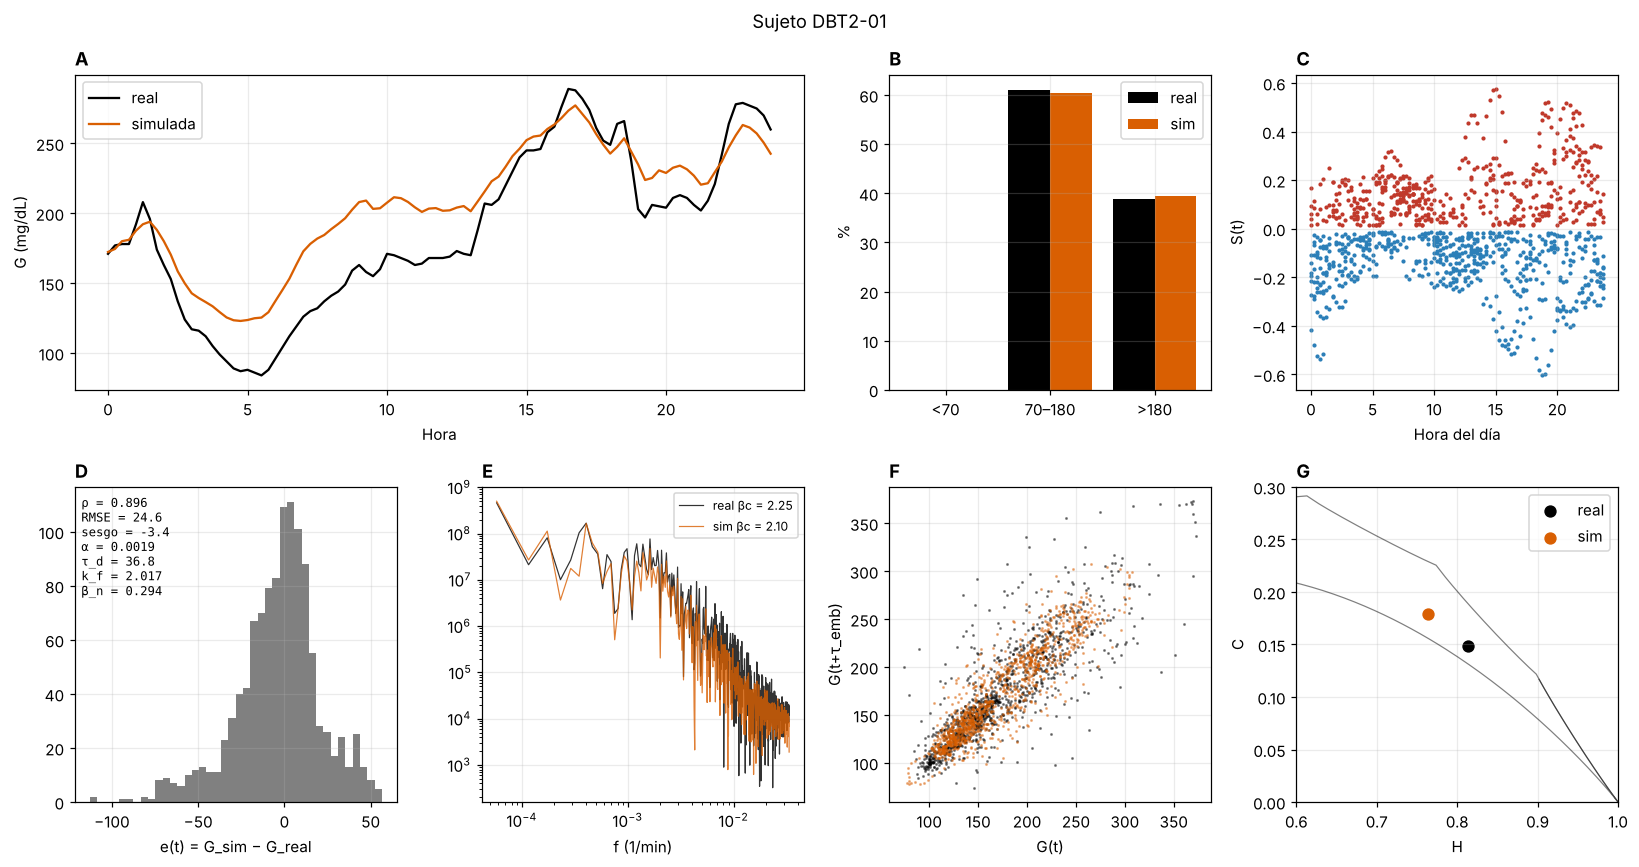

In [5]:
def panel(g, gs, p, titulo, ruta=None, dia=1):
    s = forzamiento(g)
    fig = plt.figure(figsize=(15, 8)); gsp = fig.add_gridspec(2, 4)
    t = np.arange(96) / 4; sl = slice(96 * dia, 96 * (dia + 1))
    a = fig.add_subplot(gsp[0, :2]); a.plot(t, g[sl], "k", label="real"); a.plot(t, gs[sl], color="#d95f02", label="simulada")
    a.set(xlabel="Hora", ylabel="G (mg/dL)"); a.legend(); a.set_title("A", loc="left", fontweight="bold")
    b = fig.add_subplot(gsp[0, 2]); cr, cs = sdde.metricas_clinicas(g), sdde.metricas_clinicas(gs)
    x = np.arange(3); b.bar(x - .2, [100 * cr[k] for k in ("TBR", "TIR", "TAR")], .4, color="k", label="real")
    b.bar(x + .2, [100 * cs[k] for k in ("TBR", "TIR", "TAR")], .4, color="#d95f02", label="sim")
    b.set_xticks(x, ["<70", "70–180", ">180"]); b.set_ylabel("%"); b.legend(); b.set_title("B", loc="left", fontweight="bold")
    c = fig.add_subplot(gsp[0, 3]); hd = (np.arange(len(s)) % 96) / 4
    c.scatter(hd[s > 0], s[s > 0], s=3, color="#c0392b"); c.scatter(hd[s < 0], s[s < 0], s=3, color="#2c7fb8")
    c.set(xlabel="Hora del día", ylabel="S(t)"); c.set_title("C", loc="left", fontweight="bold")
    m = sdde.metricas_ajuste(g, gs)
    d = fig.add_subplot(gsp[1, 0]); d.hist(gs - g, bins=40, color="0.5")
    d.text(.02, .97, f"ρ = {m['rho']:.3f}\nRMSE = {m['rmse']:.1f}\nsesgo = {m['sesgo']:.1f}\n"
                     f"α = {p['alpha']:.4f}\nτ_d = {p['tau_d']:.1f}\nk_f = {p['k_f']:.3f}\nβ_n = {p['beta_n']:.3f}",
           transform=d.transAxes, va="top", fontsize=8, family="monospace")
    d.set_xlabel("e(t) = G_sim − G_real"); d.set_title("D", loc="left", fontweight="bold")
    e = fig.add_subplot(gsp[1, 1])
    for y, col, lab, b_ in [(g, "k", "real", m["bc_real"]), (gs, "#d95f02", "sim", m["bc_sim"])]:
        f = np.fft.rfftfreq(len(y), d=15.0); pw = np.abs(np.fft.rfft(y)) ** 2
        e.loglog(f[1:], pw[1:], color=col, lw=.8, alpha=.8, label=f"{lab} βc = {b_:.2f}")
    e.set_xlabel("f (1/min)"); e.legend(fontsize=8); e.set_title("E", loc="left", fontweight="bold")
    f_ = fig.add_subplot(gsp[1, 2]); te = 4
    f_.plot(g[:-te], g[te:], ".", ms=2, color="k", alpha=.4); f_.plot(gs[:-te], gs[te:], ".", ms=2, color="#d95f02", alpha=.4)
    f_.set(xlabel="G(t)", ylabel="G(t+τ_emb)"); f_.set_title("F", loc="left", fontweight="bold")
    h = fig.add_subplot(gsp[1, 3]); hmin, cmin, hmax, cmax = ordinal.curvas_limite(3)
    h.plot(hmax, cmax, "k-", lw=.8, alpha=.5); h.plot(hmin, cmin, "k-", lw=.8, alpha=.5)
    h.scatter(m["H_real"], m["C_real"], c="k", s=50, label="real"); h.scatter(m["H_sim"], m["C_sim"], c="#d95f02", s=50, label="sim")
    h.set(xlim=(.6, 1), ylim=(0, .3), xlabel="H", ylabel="C"); h.legend(); h.set_title("G", loc="left", fontweight="bold")
    fig.suptitle(titulo); fig.tight_layout()
    if ruta: fig.savefig(ruta, dpi=200)
    plt.show()

panel(obs["DBT2", 1], sim["DBT2", 1], datos.parametros("DBT2", 1), "Sujeto DBT2-01", OUT / "figura_4_1_panel_DBT2_01.png")

## 5. Contribución de cada término de la ecuación (Fig. 4.2)
Sobre la trayectoria fina se evalúan los tres incrementos de (4.7): restitución
homeostática −α(G(t−τ_d) − B − Δ_b)Δt, forzamiento k_f S(t)Δt y ruido β_n ΔW. Los
incrementos se acumulan en intervalos de 15 min (la resolución del registro, 30 pasos de
integración) y se informa la fracción de la suma de varianzas que aporta cada término.

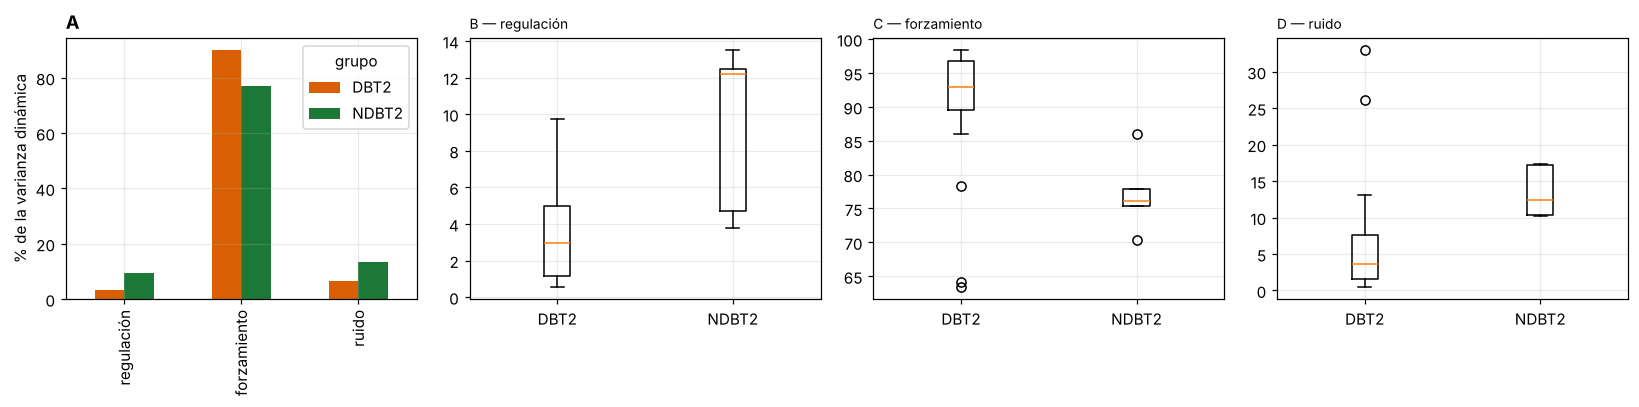

,regulación,forzamiento,ruido
grupo,,,
DBT2,3.43,89.88,6.69
NDBT2,9.34,77.14,13.52


In [6]:
def componentes(grp, i):
    g = obs[grp, i]; p = datos.parametros(grp, i)
    _, fina = sdde.simular(g, devolver_fina=True, **p)
    s_f = np.repeat(forzamiento(g), sdde.RAZON); b_f = np.repeat(sdde.referencia_por_bloques(g), sdde.RAZON)
    k = int(p["tau_d"] / sdde.DT_SIM); ruido = sdde.ruido_blanco(len(g))
    t = np.arange(k, len(fina) - 1)
    reg = -p["alpha"] * (fina[t - k] - (b_f[t] + p["delta_b"])) * sdde.DT_SIM
    frz = p["k_f"] * s_f[t] * sdde.DT_SIM
    ru = p["beta_n"] * ruido[t] * np.sqrt(sdde.DT_SIM)
    m = len(t) // sdde.RAZON * sdde.RAZON
    acum = lambda x: x[:m].reshape(-1, sdde.RAZON).sum(axis=1)   # incremento acumulado en 15 min
    v = np.array([acum(reg).var(), acum(frz).var(), acum(ru).var()])
    return 100 * v / v.sum()

desc = pd.DataFrame([dict(grupo=grp, sujeto=i, **dict(zip(["regulación", "forzamiento", "ruido"], componentes(grp, i))))
                     for grp in ("DBT2", "NDBT2") for i in (datos.IDS_DBT2 if grp == "DBT2" else datos.IDS_NDBT2_REALES)])
desc.round(2).to_csv(OUT / "figura_4_2_descomposicion.csv", index=False)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
desc.groupby("grupo")[["regulación", "forzamiento", "ruido"]].mean().T.plot.bar(ax=ax[0], color=["#d95f02", "#1b7837"])
ax[0].set_ylabel("% de la varianza dinámica"); ax[0].set_title("A", loc="left", fontweight="bold")
for a, col, l in zip(ax[1:], ["regulación", "forzamiento", "ruido"], "BCD"):
    a.boxplot([desc[desc.grupo == "DBT2"][col], desc[desc.grupo == "NDBT2"][col]], tick_labels=["DBT2", "NDBT2"])
    a.set_title(f"{l} — {col}", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "figura_4_2_descomposicion.png", dpi=200); plt.show()
desc.groupby("grupo")[["regulación", "forzamiento", "ruido"]].mean().round(2)

## 6. Validación generativa estocástica (Sec. 4.6.3)
Máximo exponente de Lyapunov de la serie real y de la simulada (realización de ruido
independiente del residuo del ajuste).

In [7]:
lle = pd.DataFrame([dict(grupo=grp, sujeto=i, LLE_real=no_lineal.lyapunov(obs[grp, i]), LLE_sim=no_lineal.lyapunov(sim[grp, i]))
                    for grp in ("DBT2", "NDBT2") for i in (datos.IDS_DBT2 if grp == "DBT2" else datos.IDS_NDBT2_REALES)])
lle["T_L_real"], lle["T_L_sim"] = 1 / lle.LLE_real, 1 / lle.LLE_sim
lle.round(3).to_csv(OUT / "validacion_generativa_lyapunov.csv", index=False)
lle.groupby("grupo")[["LLE_real", "LLE_sim", "T_L_real", "T_L_sim"]].agg(["mean", "std"]).round(3)

LLE_real        LLE_sim        T_L_real        T_L_sim       
          mean    std    mean    std     mean    std    mean    std
grupo                                                              
DBT2     0.387  0.048   0.445  0.043    2.619  0.291   2.264  0.206
NDBT2    0.271  0.016   0.315  0.041    3.694  0.221   3.223  0.432

## 7. Calibración con Optuna (opcional)
Cambiar `CALIBRAR = True` para ajustar un sujeto desde cero con la función objetivo (4.23).
Con 300 ensayos tarda varios minutos por sujeto. Para la corrida completa:
`python scripts/calibrar_modelo.py --grupo DBT2`.

In [8]:
CALIBRAR = False
if CALIBRAR:
    g = obs["DBT2", 1]
    mejor, estudio = sdde.ajustar(g, n_ensayos=300, semilla_optuna=42, filtro_sg=True)
    print(mejor)
    print(sdde.metricas_ajuste(g, sdde.simular(g, filtro_sg=True, **mejor)))

## Verificación contra la tesis (Tabla 4.2 y texto de la Sec. 4.5)

In [9]:
tesis_42 = {  # Tabla 4.2 completa: (rho, RMSE, sesgo, bc_real, bc_sim, dHC, TIR_real, TIR_sim)
    ("DBT2", 1): (0.896, 24.6, -3.4, 2.25, 2.1, 0.058, 61.1, 60.5),
    ("DBT2", 2): (0.821, 23.7, 0.7, 2.34, 2.8, 0.068, 85.0, 84.3),
    ("DBT2", 3): (0.864, 12.9, 0.4, 2.5, 2.85, 0.067, 96.5, 97.9),
    ("DBT2", 4): (0.67, 15.4, -0.2, 2.58, 2.56, 0.013, 99.0, 99.7),
    ("DBT2", 5): (0.842, 28.9, 0.0, 2.81, 3.24, 0.066, 70.5, 72.9),
    ("DBT2", 6): (0.715, 14.6, -0.6, 2.58, 2.83, 0.05, 99.0, 100.0),
    ("DBT2", 7): (0.755, 16.3, -0.1, 2.33, 2.91, 0.055, 96.3, 97.5),
    ("DBT2", 8): (0.709, 17.5, 0.2, 2.27, 2.43, 0.027, 90.9, 91.7),
    ("DBT2", 9): (0.789, 14.3, 0.8, 2.39, 2.86, 0.079, 95.7, 96.9),
    ("DBT2", 10): (0.769, 14.1, -0.5, 2.17, 2.59, 0.064, 97.0, 96.5),
    ("DBT2", 11): (0.765, 17.5, 0.1, 2.35, 2.42, 0.01, 93.8, 93.8),
    ("DBT2", 12): (0.707, 16.4, 1.9, 1.95, 2.37, 0.012, 97.1, 97.6),
    ("DBT2", 13): (0.808, 12.4, -0.0, 2.11, 2.43, 0.052, 96.3, 98.4),
    ("DBT2", 14): (0.858, 14.2, -0.1, 2.45, 2.89, 0.071, 93.4, 94.5),
    ("DBT2", 15): (0.807, 12.9, 0.1, 2.23, 2.57, 0.041, 99.4, 99.7),
    ("DBT2", 16): (0.786, 16.2, -0.9, 2.22, 2.73, 0.079, 93.8, 97.0),
    ("DBT2", 17): (0.894, 18.4, -1.8, 2.24, 2.31, 0.062, 82.6, 82.7),
    ("DBT2", 18): (0.854, 12.2, 0.1, 2.16, 2.81, 0.068, 97.8, 98.3),
    ("DBT2", 19): (0.814, 15.7, 0.4, 2.21, 2.67, 0.099, 91.8, 94.0),
    ("DBT2", 20): (0.867, 26.8, 1.0, 2.46, 2.58, 0.093, 56.9, 53.5),
    ("NDBT2", 1): (0.549, 10.0, -0.4, 1.75, 1.92, 0.029, 96.3, 97.1),
    ("NDBT2", 2): (0.641, 11.2, 0.2, 1.81, 2.02, 0.045, 75.7, 75.3),
    ("NDBT2", 3): (0.674, 11.5, 0.2, 1.91, 2.0, 0.004, 95.7, 95.7),
    ("NDBT2", 4): (0.557, 14.4, -0.1, 1.78, 1.81, 0.008, 99.0, 99.5),
    ("NDBT2", 5): (0.692, 9.7, 0.2, 2.1, 2.36, 0.028, 99.0, 99.6),
    ("NDBT2", 6): (0.697, 7.2, 0.1, 1.86, 2.02, 0.027, 95.3, 95.7),
    ("NDBT2", 7): (0.716, 12.4, -0.4, 1.8, 2.02, 0.034, 80.7, 80.7),
    ("NDBT2", 8): (0.695, 13.2, -0.4, 1.8, 2.18, 0.058, 98.3, 98.1),
    ("NDBT2", 9): (0.792, 13.2, -0.0, 1.93, 2.3, 0.044, 41.9, 40.5),
    ("NDBT2", 10): (0.684, 11.2, -0.9, 1.77, 1.94, 0.069, 62.1, 62.6),
    ("NDBT2", 11): (0.733, 12.2, 0.0, 2.07, 2.31, 0.037, 98.0, 98.8),
    ("NDBT2", 12): (0.766, 14.2, -0.2, 1.85, 2.18, 0.035, 86.6, 85.8),
    ("NDBT2", 13): (0.702, 12.7, 0.2, 1.92, 1.99, 0.036, 88.8, 89.0),
    ("NDBT2", 14): (0.634, 10.0, 0.3, 1.79, 1.83, 0.015, 90.8, 91.2),
    ("NDBT2", 15): (0.657, 10.8, 0.2, 1.87, 1.93, 0.007, 97.9, 97.9),
    ("NDBT2", 16): (0.681, 8.6, -0.2, 1.83, 1.99, 0.032, 99.9, 100.0),
    ("NDBT2", 17): (0.694, 11.9, 0.5, 1.7, 2.15, 0.048, 43.1, 43.5),
    ("NDBT2", 18): (0.52, 10.6, -0.3, 1.82, 1.8, 0.001, 98.1, 99.0),
    ("NDBT2", 19): (0.713, 15.5, 0.2, 1.95, 2.08, 0.039, 92.4, 93.1),
    ("NDBT2", 20): (0.75, 13.2, 0.4, 1.79, 2.05, 0.043, 91.1, 91.1)}
cols = ["rho", "RMSE", "sesgo", "bc_real", "bc_sim", "dHC", "TIR_real", "TIR_sim"]
dec = [3, 1, 1, 2, 2, 3, 1, 1]
ver = []
for (grp, i), vals in tesis_42.items():
    fila = t42[(t42.grupo == grp) & (t42.sujeto == i)].iloc[0]
    ok = all(abs(round(fila[c], d) - v) < 1e-9 or (abs(v) < 1e-9 and abs(round(fila[c], d)) < 1e-9) for c, d, v in zip(cols, dec, vals))
    ver.append(dict(serie=f"{grp}-{i:02d}", tesis=vals, reproducido=tuple(round(fila[c], d) for c, d in zip(cols, dec)), coincide="✔" if ok else "✘"))
g_d = t42[t42.grupo == "DBT2"]
ver.append(dict(serie="DBT2 media ρ ± DE", tesis=(0.80, 0.06), reproducido=(round(g_d.rho.mean(), 2), round(g_d.rho.std(ddof=0), 2)),
                coincide="✔" if (round(g_d.rho.mean(), 2), round(g_d.rho.std(ddof=0), 2)) == (0.80, 0.06) else "✘"))
ver.append(dict(serie="DBT2 media RMSE ± DE", tesis=(17.3, 4.8), reproducido=(round(g_d.RMSE.mean(), 1), round(g_d.RMSE.std(ddof=0), 1)),
                coincide="✔" if (round(g_d.RMSE.mean(), 1), round(g_d.RMSE.std(ddof=0), 1)) == (17.3, 4.8) else "✘"))
def bloque(nombre, d, tesis):
    obt = (round(d.rho.mean(), 2), round(d.rho.std(ddof=0), 2), round(d.RMSE.mean(), 1), round(d.RMSE.std(ddof=0), 1),
           round(d.sesgo.mean(), 1), round(d.sesgo.std(ddof=0), 1), round(d.bc_real.mean(), 2), round(d.bc_sim.mean(), 2),
           round(d.dHC.mean(), 3), round(d.dHC.std(ddof=0), 3), round(d.TIR_real.mean(), 1), round(d.TIR_sim.mean(), 1))
    ok = all(abs(a - b) < 1e-9 or (abs(a) < 1e-9 and abs(b) < 1e-9) for a, b in zip(obt, tesis))
    ver.append(dict(serie=nombre, tesis=tesis, reproducido=obt, coincide="✔" if ok else "✘"))

# (ρ, DE, RMSE, DE, sesgo, DE, βc real, βc sim, dHC, DE, TIR real, TIR sim) — filas «Media ± DE» de la Tabla 4.2
bloque("Media ± DE DBT2", g_d, (0.80, 0.06, 17.3, 4.8, -0.1, 1.1, 2.33, 2.65, 0.057, 0.025, 89.7, 90.4))
bloque("Media ± DE NDBT2 real", t42[(t42.grupo == "NDBT2") & (t42.sujeto <= 5)], (0.62, 0.06, 11.3, 1.7, 0.0, 0.2, 1.87, 2.02, 0.023, 0.015, 93.1, 93.4))
bloque("Media ± DE NDBT2 aumentado", t42[(t42.grupo == "NDBT2") & (t42.sujeto > 5)], (0.70, 0.06, 11.8, 2.1, -0.0, 0.3, 1.85, 2.05, 0.035, 0.017, 84.3, 84.5))
ver.append(dict(serie="Trayectorias bit a bit", tesis=40, reproducido=sum(coinciden), coincide="✔" if all(coinciden) else "✘"))
ver = pd.DataFrame(ver); ver.to_csv(OUT / "verificacion_cap4.csv", index=False); ver

,serie,tesis,reproducido,coincide
0,DBT2-01,"(0.896, 24.6, -3.4, 2.25, 2.1, 0.058, 61.1, 60.5)","(0.896, 24.6, -3.4, 2.25, 2.1, 0.058, 61.1, 60.5)",✔
1,DBT2-02,"(0.821, 23.7, 0.7, 2.34, 2.8, 0.068, 85.0, 84.3)","(0.821, 23.7, 0.7, 2.34, 2.8, 0.068, 85.0, 84.3)",✔
2,DBT2-03,"(0.864, 12.9, 0.4, 2.5, 2.85, 0.067, 96.5, 97.9)","(0.864, 12.9, 0.4, 2.5, 2.85, 0.067, 96.5, 97.9)",✔
3,DBT2-04,"(0.67, 15.4, -0.2, 2.58, 2.56, 0.013, 99.0, 99.7)","(0.67, 15.4, -0.2, 2.58, 2.56, 0.013, 99.0, 99.7)",✔
4,DBT2-05,"(0.842, 28.9, 0.0, 2.81, 3.24, 0.066, 70.5, 72.9)","(0.842, 28.9, 0.0, 2.81, 3.24, 0.066, 70.5, 72.9)",✔
5,DBT2-06,"(0.715, 14.6, -0.6, 2.58, 2.83, 0.05, 99.0, 10...","(0.715, 14.6, -0.6, 2.58, 2.83, 0.05, 99.0, 10...",✔
6,DBT2-07,"(0.755, 16.3, -0.1, 2.33, 2.91, 0.055, 96.3, 9...","(0.755, 16.3, -0.1, 2.33, 2.91, 0.055, 96.3, 9...",✔
7,DBT2-08,"(0.709, 17.5, 0.2, 2.27, 2.43, 0.027, 90.9, 91.7)","(0.709, 17.5, 0.2, 2.27, 2.43, 0.027, 90.9, 91.7)",✔
8,DBT2-09,"(0.789, 14.3, 0.8, 2.39, 2.86, 0.079, 95.7, 96.9)","(0.789, 14.3, 0.8, 2.39, 2.86, 0.079, 95.7, 96.9)",✔
9,DBT2-10,"(0.769, 14.1, -0.5, 2.17, 2.59, 0.064, 97.0, 9...","(0.769, 14.1, -0.5, 2.17, 2.59, 0.064, 97.0, 9...",✔
